In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Environment ready!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Environment ready!
Pandas: 3.0.6
NumPy: 2.5.4


In [5]:
df = pd.read_csv("../data/fake_job_postings.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (17880, 18)


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   job_id               17880 non-null  int64
 1   title                17880 non-null  str  
 2   location             17534 non-null  str  
 3   department           6333 non-null   str  
 4   salary_range         2868 non-null   str  
 5   company_profile      14572 non-null  str  
 6   description          17879 non-null  str  
 7   requirements         15184 non-null  str  
 8   benefits             10668 non-null  str  
 9   telecommuting        17880 non-null  int64
 10  has_company_logo     17880 non-null  int64
 11  has_questions        17880 non-null  int64
 12  employment_type      14409 non-null  str  
 13  required_experience  10830 non-null  str  
 14  required_education   9775 non-null   str  
 15  industry             12977 non-null  str  
 16  function             11425 non-nu

In [8]:
display(df.isnull().sum().sort_values(ascending=False))

salary_range           15012
department             11547
required_education      8105
benefits                7212
required_experience     7050
function                6455
industry                4903
employment_type         3471
company_profile         3308
requirements            2696
location                 346
description                1
title                      0
job_id                     0
telecommuting              0
has_questions              0
has_company_logo           0
fraudulent                 0
dtype: int64

In [9]:
print(df["fraudulent"].value_counts())

fraudulent
0    17014
1      866
Name: count, dtype: int64


In [10]:
df["fraudulent"].value_counts(normalize=True).mul(100).round(2)

fraudulent
0    95.16
1     4.84
Name: proportion, dtype: float64

In [11]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [12]:
text_columns = [
    "title",
    "company_profile",
    "description",
    "requirements",
    "benefits"
]

df[text_columns].isnull().sum()

title                 0
company_profile    3308
description           1
requirements       2696
benefits           7212
dtype: int64

In [13]:
df["fraudulent"].value_counts()

fraudulent
0    17014
1      866
Name: count, dtype: int64

In [14]:
df[text_columns] = df[text_columns].fillna("")

In [15]:
df["combined_text"] = (
    df["title"] + " " +
    df["company_profile"] + " " +
    df["description"] + " " +
    df["requirements"] + " " +
    df["benefits"]
)

df[["combined_text", "fraudulent"]].head()

,combined_text,fraudulent
0,"Marketing Intern We're Food52, and we've creat...",0
1,Customer Service - Cloud Video Production 90 S...,0
2,Commissioning Machinery Assistant (CMA) Valor ...,0
3,Account Executive - Washington DC Our passion ...,0
4,Bill Review Manager SpotSource Solutions LLC i...,0


In [16]:
print("Missing values:", df["combined_text"].isnull().sum())
print("Empty text rows:", (df["combined_text"].str.strip() == "").sum())

Missing values: 0
Empty text rows: 0


In [17]:
from sklearn.model_selection import train_test_split

X = df["combined_text"]
y = df["fraudulent"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 14304
Testing samples: 3576


In [18]:
print("Training fraud distribution:")
print(y_train.value_counts())

print("\nTesting fraud distribution:")
print(y_test.value_counts())

Training fraud distribution:
fraudulent
0    13611
1      693
Name: count, dtype: int64

Testing fraud distribution:
fraudulent
0    3403
1     173
Name: count, dtype: int64


In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    stop_words="english",
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

Training matrix: (14304, 10000)
Testing matrix: (3576, 10000)


In [20]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(class_weight="balanced", max_iter=1000)

model.fit(X_train_tfidf, y_train)

print("Model training complete!")

Model training complete!


In [21]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = model.predict(X_test_tfidf)

print(classification_report(y_test, y_pred, target_names=["Legitimate", "Fraudulent"]))

              precision    recall  f1-score   support

  Legitimate       0.99      0.98      0.99      3403
  Fraudulent       0.68      0.90      0.78       173

    accuracy                           0.98      3576
   macro avg       0.84      0.94      0.88      3576
weighted avg       0.98      0.98      0.98      3576



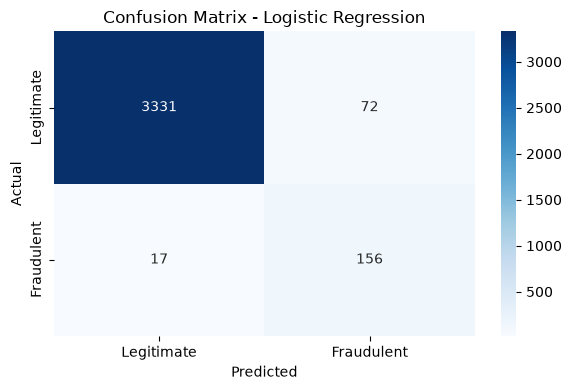

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraudulent"],
    yticklabels=["Legitimate", "Fraudulent"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()

In [23]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

nb_pred = nb_model.predict(X_test_tfidf)

print(classification_report(
    y_test,
    nb_pred,
    target_names=["Legitimate", "Fraudulent"]
))

              precision    recall  f1-score   support

  Legitimate       0.97      0.99      0.98      3403
  Fraudulent       0.67      0.36      0.47       173

    accuracy                           0.96      3576
   macro avg       0.82      0.67      0.72      3576
weighted avg       0.95      0.96      0.95      3576



In [24]:
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report

svm_model = LinearSVC(class_weight="balanced", random_state=42)

svm_model.fit(X_train_tfidf, y_train)

svm_pred = svm_model.predict(X_test_tfidf)

print(classification_report(
    y_test,
    svm_pred,
    target_names=["Legitimate", "Fraudulent"]
))

              precision    recall  f1-score   support

  Legitimate       0.99      0.99      0.99      3403
  Fraudulent       0.84      0.83      0.83       173

    accuracy                           0.98      3576
   macro avg       0.91      0.91      0.91      3576
weighted avg       0.98      0.98      0.98      3576



In [25]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
import pandas as pd

results = []

for name, predictions in [
    ("Logistic Regression", y_pred),
    ("Naive Bayes", nb_pred),
    ("Linear SVM", svm_pred)
]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Fraud Precision": precision_score(y_test, predictions, pos_label=1),
        "Fraud Recall": recall_score(y_test, predictions, pos_label=1),
        "Fraud F1": f1_score(y_test, predictions, pos_label=1)
    })

results_df = pd.DataFrame(results)
display(results_df.round(3))

,Model,Accuracy,Fraud Precision,Fraud Recall,Fraud F1
0,Logistic Regression,0.975,0.684,0.902,0.778
1,Naive Bayes,0.960,0.667,0.358,0.466
2,Linear SVM,0.984,0.836,0.827,0.831


In [29]:
def predict_job(text):
    text_tfidf = tfidf.transform([text])
    prediction = svm_model.predict(text_tfidf)[0]

    if prediction == 1:
        print("Potentially FRAUDULENT job posting")
    else:
        print("Likely LEGITIMATE job posting")


sample_job = """
Work from home and earn $5000 weekly!
No experience required. Pay a registration fee to get started.
Send your bank details immediately to secure your position.
"""

predict_job(sample_job)

Potentially FRAUDULENT job posting


In [30]:
sample_job_2 = """
Software Engineer
We are seeking a Python developer with experience in SQL,
Git, and software development. Applicants will complete
a technical interview. Salary and benefits are discussed
during the recruitment process.
"""

predict_job(sample_job_2)

Likely LEGITIMATE job posting


In [28]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(svm_model, "../models/fake_job_svm.pkl")
joblib.dump(tfidf, "../models/tfidf_vectorizer.pkl")

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!


In [31]:
results_df.to_csv("../models/model_comparison.csv", index=False)
print("Model comparison saved!")

Model comparison saved!


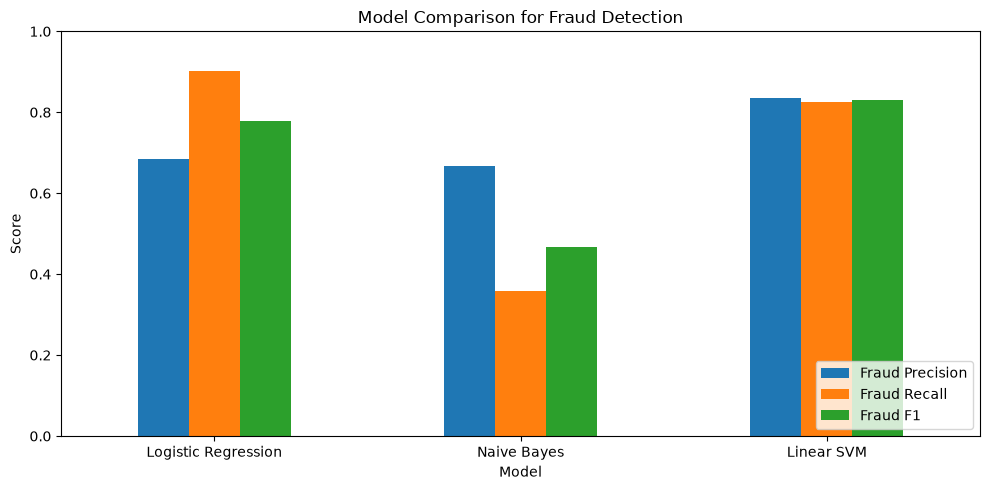

In [32]:
import matplotlib.pyplot as plt

metrics = ["Fraud Precision", "Fraud Recall", "Fraud F1"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("Model Comparison for Fraud Detection")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [34]:
print("FAKE JOB POSTING DETECTION")
print("=" * 35)
print(f"Dataset size: {len(df)}")
print(f"Best model by Fraud F1: Linear SVM")
print(f"Fraud F1-score: {f1_score(y_test, svm_pred):.3f}")
print(f"Fraud Precision: {precision_score(y_test, svm_pred):.3f}")
print(f"Fraud Recall: {recall_score(y_test, svm_pred):.3f}")

FAKE JOB POSTING DETECTION
Dataset size: 17880
Best model by Fraud F1: Linear SVM
Fraud F1-score: 0.831
Fraud Precision: 0.836
Fraud Recall: 0.827


In [35]:
import os

print("SVM model exists:", os.path.exists("../models/fake_job_svm.pkl"))
print("TF-IDF vectorizer exists:", os.path.exists("../models/tfidf_vectorizer.pkl"))
print("Comparison table exists:", os.path.exists("../models/model_comparison.csv"))

SVM model exists: True
TF-IDF vectorizer exists: True
Comparison table exists: True


In [2]:
import joblib

loaded_model = joblib.load("../models/fake_job_svm.pkl")
loaded_tfidf = joblib.load("../models/tfidf_vectorizer.pkl")

sample = """
Work from home and earn $5000 weekly!
No experience required. Pay a registration fee to get started.
Send your bank details immediately to secure your position.
"""

sample_features = loaded_tfidf.transform([sample])
prediction = loaded_model.predict(sample_features)[0]

print("Prediction:", "Potentially Fraudulent" if prediction == 1 else "Likely Legitimate")

Prediction: Potentially Fraudulent


In [10]:
def demo_job(title, description):
    text = title + " " + description
    features = loaded_tfidf.transform([text])
    prediction = loaded_model.predict(features)[0]

    print("Job Title:", title)
    print("Prediction:", "POTENTIALLY FRAUDULENT"
          if prediction == 1 else "LIKELY LEGITIMATE")